In [1]:
# 손 글씨 이미지 데이터를 분류하는 선형 분류모델을 만들자
# 선형 분류 모델의 알고리즘 학습
# 이미지 데이터에 대한 기초지식 습득

In [2]:
# 라이브러리 불러오기
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [3]:
# 데이터 불러오기(변수명 : data), index_col = 인덱스할 컬럼
data = pd.read_csv('data/digit_train.csv')

In [4]:
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# 이미지 42000장
# 특성 785개, 정답데이터 1 + 784 이미지 데이터

data.shape

(42000, 785)

In [6]:
# 이미지 데이터(x)와 라벨데이터(y) 분리
x = data.drop('label', axis = 1)
y = data['label']

In [7]:
# 이미지 출력
# 가장 앞 이미지 1장
img = x.loc[0].values

# 제곱근 구하기
784 ** 0.5

# 784개의 1차원 데이터를 -> 28 * 28형태의 이미지 데이터로 변환
img_re = img.reshape(28,28)
img_re

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0, 188, 255,  94,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0, 191, 250, 253,  93,   0,   0,   0,
          0,   0],
       [  

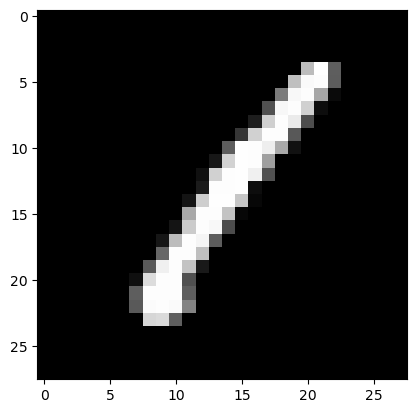

In [8]:
# 이미지 출력
# 우리가 보는 색상 체계는 3단계, rgb
# 흑백이미지거나 컬러이미지거나
plt.imshow(img_re, cmap = 'gray' )
plt.show()

In [9]:
img_re

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0, 188, 255,  94,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0, 191, 250, 253,  93,   0,   0,   0,
          0,   0],
       [  

In [13]:
# 이미지데이터의 경우, 2차원으로 구성되어 있다.
# 대부분의 모델들은 입력데이터로 2차원 데이터로 받을 수 없다
# y = wx + b라는 수식에서 x값에 list가 들어가지 못함
# 2차원데이터를 1차원으로 변환해서 학습

# x_train, y_train, x_test, y_test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 7)

In [11]:
#선형 분류 모델을 활용해서 손글씨 데이터 분류
# 선형 모델 : 각 특성들마다 알맞은 가중치를 매겨주는 모델
#           : 가중치와 특성들의 곱셈을 전부 합함 -> y = w1w1 * w2w2
# 회귀 : y값을 예측 그 자체로 사용
# 분류 : y값이 0이상 양성(1), 0미만이면 음성(0)

In [14]:
# 모델 불러오기
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(x_train, y_train)

C:\Users\smart\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [15]:
x_test.iloc[0]
y_test.iloc[0]

model.predict([x_test.iloc[0]])

C:\Users\smart\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [17]:
# 어느정도의 확신도로 1이라고 예측하는가?
pre = model.predict_proba([x_test.iloc[0]]).round(3)

# argmax -> 배열안에서 가장 높은 값이 들어있는 인덱스 위치 반환
np.argmax(pre)

C:\Users\smart\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


np.int64(1)

In [18]:
# Logistic Regression(선형 분류) 하이퍼파라미터
# max_iter : 반복학습
# pendlty(l1, l2) : 가중치 규제 -> 과대적합 제어

# L1(Lasso 규제) : 절대값으로 가중치를 깎음
# -> 불필요한 자잘한 특성을 제거하기 위해 사용한다 : 중요한 애들만 남김
# L2 (Ridge 규제) : 일정 퍼센트만큼 가중치를 깎음
# -> 

# 1000번 동안 학습을 반복했지만 학습 횟수가 모자랐다. 경고발생
model = LogisticRegression(max_iter = 1000)

# 최적의 가중치란 오차가 가장 작은 가중치다
# 경사하강법은 오차의 기울기를 구해서, 오차가 낮아지는 방향으로 점진적으로 이용하는 방법
model.fit(x_train, y_train)

C:\Users\smart\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'
